# Time Series Anomaly Detection for KPI Monitoring

**What you'll learn**

- How to build a KPI monitoring test bed the way you'd validate a production detector: a year
  of a business metric (trend × weekly seasonality × noise) with **labeled, typed injected
  anomalies** — point spikes, a level shift, a gradual drift, and seasonal violations
  ("Sunday-shaped traffic on a Tuesday").
- Three detector families implemented and scored against those labels: **STL residual +
  robust (MAD) z-score**, **rolling one-step forecast + prediction-interval breach**, and
  **IsolationForest on engineered features** — plus a **CUSUM changepoint watchdog** for what
  the first three structurally miss.
- The mapping that is the actual lesson: **point vs contextual vs collective anomalies**, and
  which detector family catches which — with a detection-delay table, not vibes.
- Alert design as an engineering problem: why a static threshold on a growing seasonal metric
  is doomed, thresholds as **alert budgets**, alert fatigue economics, and holiday handling.
- Root-cause first steps: **dimensional breakdown** to localize which segment moved, in code.

**Why it matters in interviews**

- "Design anomaly detection / alerting for our metrics platform" is a staple senior DS/AS
  system-design question (Datadog, Amazon CloudWatch, Meta, Uber, LinkedIn all run versions
  of this internally). The expected answer is forecast-residual + budget-based thresholds +
  dedup — exactly what this notebook builds.
- "Your detector missed a slow revenue decline — why?" tests whether you know that one-step
  detectors are structurally blind to drift (collective anomalies) and that accumulation
  (CUSUM) is the fix.
- "Level shift vs outlier — does the treatment differ?" separates candidates who have
  operated monitoring systems from those who have only read about them.
- "How do you tune thresholds with no labels?" is the classic unsupervised-evaluation trap;
  alert budgets and synthetic injection (this notebook's method) are the strong answers.

Prerequisites: decomposition and seasonality from
[01_ts_foundations.ipynb](./01_ts_foundations.ipynb), forecasting and prediction intervals
from [02_classical_forecasting.ipynb](./02_classical_forecasting.ipynb). The precision /
alert-fatigue economics at low base rates is developed in depth in
[../04_ml_tabular/04_imbalanced_fraud.ipynb](../04_ml_tabular/04_imbalanced_fraud.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import median_abs_deviation
from statsmodels.tsa.seasonal import STL
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (9.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.precision", 3)

## 1. The scenario: a year of daily sessions, with ground truth

You own the "daily sessions" KPI for a product growing ~30%/year, with a strong weekly
cycle (weekends run 20–30% below weekdays) and ~2.5% day-to-day multiplicative noise.
We simulate it **multiplicatively** — trend × day-of-week factor × lognormal noise — because
that is how traffic metrics actually behave: a "10% drop" means 10% at any level of the
metric. All modeling below therefore happens on the **log scale**, where the structure is
additive and residual variance is stable across the year (Pitfall 4 shows what happens if
you skip this).

Then we inject **seven labeled anomalies of four types**:

| type | events | real-world story |
|---|---|---|
| **point** (single day, large residual) | +28% spike, −22% dip, +8% subtle spike | press hit / bot wave; checkout outage; small campaign |
| **contextual** (value normal *globally*, wrong for its context) | Tuesday with Sunday-shaped traffic; Saturday with weekday-shaped traffic | public holiday; flash sale |
| **collective — level shift** (each day mildly off, jointly a regime change) | −12% for 28 days | SDK release silently breaks logging on one platform |
| **collective — drift** (slow ramp) | 0 → −12% over 35 days | referral partner gradually losing traffic |

Labels are the point of the exercise: without ground truth you cannot say *which detector
catches which anomaly type*, and that mapping is the design knowledge interviewers probe.

In [2]:
n_days = 364                                   # exactly 52 weeks
dates = pd.date_range("2025-01-06", periods=n_days, freq="D")   # starts on a Monday
dow = dates.dayofweek.to_numpy()               # Mon=0 ... Sun=6

BASE = 50_000
GROWTH = 1.30                                  # +30% over the year
DOW_FACTOR = np.array([1.00, 1.03, 1.05, 1.04, 0.99, 0.80, 0.72])  # Mon..Sun
NOISE_SD = 0.025                               # multiplicative (log-scale) noise

trend = BASE * GROWTH ** (np.arange(n_days) / n_days)
clean = trend * DOW_FACTOR[dow]                # noiseless, anomaly-free truth
noise = np.exp(rng.normal(0.0, NOISE_SD, n_days))

# ---- labeled anomaly injection (multiplicative effects) ----
effect = np.zeros(n_days)
effect[93] = +0.28                             # point: press hit / bot wave (a Wednesday)
effect[129] = -0.22                            # point: partial-day checkout outage (a Thursday)
effect[300] = +0.08                            # point: subtle campaign bump (a Sunday)
effect[106] = DOW_FACTOR[6] / DOW_FACTOR[1] - 1   # contextual: Tue behaves like a Sun (holiday)
effect[313] = DOW_FACTOR[2] / DOW_FACTOR[5] - 1   # contextual: Sat behaves like a Wed (flash sale)
effect[182:210] = -0.12                        # collective: 28-day level shift
effect[240:275] = -0.12 * (np.arange(35) + 1) / 35  # collective: 35-day linear drift to -12%

events = [
    {"name": "spike +28%",        "type": "point",      "start": 93,  "end": 93},
    {"name": "holiday Tue",       "type": "contextual", "start": 106, "end": 106},
    {"name": "outage dip -22%",   "type": "point",      "start": 129, "end": 129},
    {"name": "level shift -12%",  "type": "collective", "start": 182, "end": 209},
    {"name": "drift 0 to -12%",   "type": "collective", "start": 240, "end": 274},
    {"name": "subtle spike +8%",  "type": "point",      "start": 300, "end": 300},
    {"name": "flash-sale Sat",    "type": "contextual", "start": 313, "end": 313},
]

sessions = clean * noise * (1 + effect)
is_anom = effect != 0
kpi = pd.DataFrame({"sessions": sessions, "dow": dow, "is_anom": is_anom}, index=dates)
ly = np.log(sessions)

print(f"days: {n_days}, labeled anomalous days: {is_anom.sum()} "
      f"({is_anom.mean():.1%} of days), events: {len(events)}")

days: 364, labeled anomalous days: 68 (18.7% of days), events: 7


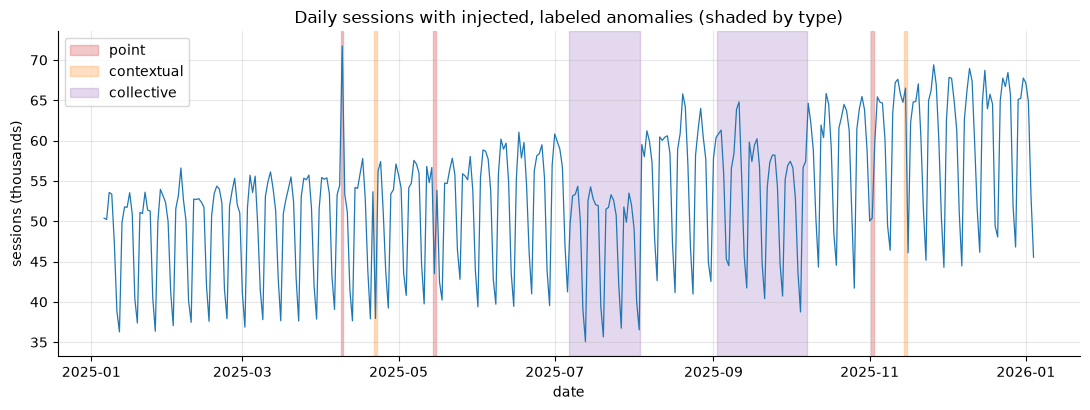

In [3]:
EVENT_COLOR = {"point": "tab:red", "contextual": "tab:orange", "collective": "tab:purple"}

def mark_events(ax):
    seen = set()
    for ev in events:
        lab = ev["type"] if ev["type"] not in seen else None
        seen.add(ev["type"])
        ax.axvspan(dates[ev["start"]] - pd.Timedelta(hours=12),
                   dates[ev["end"]] + pd.Timedelta(hours=12),
                   color=EVENT_COLOR[ev["type"]], alpha=0.25, label=lab)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(dates, sessions / 1000, lw=0.9, color="tab:blue")
mark_events(ax)
ax.set_title("Daily sessions with injected, labeled anomalies (shaded by type)")
ax.set_xlabel("date"); ax.set_ylabel("sessions (thousands)")
ax.legend(loc="upper left")
plt.show()

Eyeball check before any math: the two big point events and the holiday are visible; the
subtle +8% spike is not; the level shift and the drift hide inside the weekly oscillation
unless you squint. **The dangerous anomalies are precisely the ones a human scanning 500
dashboards will not see.** Note also that the outage dip (−22% on a Thursday) lands the
metric at roughly *Saturday's normal level* — on a seasonal series, even "point" anomalies
are anomalous relative to context, not relative to the global range. Any global threshold
is fighting the seasonality before it fights the anomalies.

## 2. Method 1 — STL residual + robust z-score (MAD)

Decompose log-sessions into trend + weekly seasonal + remainder with STL (`robust=True` so
outliers don't drag the trend and seasonal fits), then score the remainder with a **robust
z-score**: center by the median, scale by MAD (scaled to be σ-consistent under normality).
Why MAD and not the standard deviation? The residual distribution *contains the anomalies
you're trying to find* — a single 10σ spike inflates a plain std enough to mask everything
else (Pitfall 1 quantifies this). Robust scale estimation is not optional in anomaly
detection; it's the difference between a detector and a decoration.

Two properties to keep in mind for the scoreboard later:

- STL is **two-sided**: the trend/seasonal at time *t* use data *after t*. This is a batch /
  retrospective method — great for backfills, data-quality audits, and labeling historical
  incidents; not directly usable for this-morning alerting.
- STL's trend is flexible. It will **absorb a level shift or drift within roughly a trend
  window** (~2 weeks at period 7), leaving large residuals only near the edges. That is a
  feature for decomposition and a bug for changepoint detection.

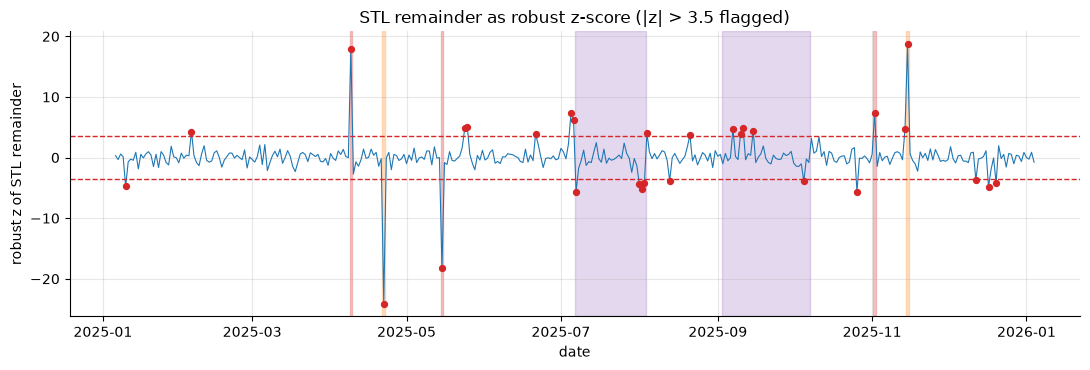

STL flags 29 days


In [4]:
stl_fit = STL(pd.Series(ly, index=dates), period=7, robust=True).fit()
stl_resid = stl_fit.resid.to_numpy()

stl_z = (stl_resid - np.median(stl_resid)) / median_abs_deviation(stl_resid, scale="normal")
STL_THRESH = 3.5
stl_flag = np.abs(stl_z) > STL_THRESH

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(dates, stl_z, lw=0.8, color="tab:blue")
ax.axhline(STL_THRESH, color="tab:red", ls="--", lw=1)
ax.axhline(-STL_THRESH, color="tab:red", ls="--", lw=1)
ax.scatter(dates[stl_flag], stl_z[stl_flag], color="tab:red", s=18, zorder=3)
mark_events(ax)
ax.set_title(f"STL remainder as robust z-score (|z| > {STL_THRESH} flagged)")
ax.set_xlabel("date"); ax.set_ylabel("robust z of STL remainder")
plt.show()
print(f"STL flags {stl_flag.sum()} days")

The spikes, the outage, and both contextual anomalies produce huge robust z-scores — the
seasonal fit knows what a Tuesday *should* look like, so Sunday-shaped traffic on a Tuesday
is a ~10σ residual even though the raw value is unremarkable. Inside the level shift and the
drift the residuals collapse back toward zero: the trend followed the anomaly. Remember this
shape — it reappears in every locally-adaptive method.

## 3. Method 2 — rolling forecast + prediction-interval breach

The production workhorse. Each morning, fit a small model on a **trailing window** (8 weeks
here: log-linear trend + day-of-week dummies), forecast today, and alert if the actual lands
outside `forecast ± z·s`. Two deliberately senior choices in the implementation:

- **Robust interval width**: `s` is the MAD (σ-consistent) of training residuals, not the
  std — yesterday's incident must not widen today's interval (Pitfall 1 again).
- **One-sided honesty**: we use the plain `z·s` band and ignore parameter-estimation
  variance; with 56 training points and 8 parameters that understates width slightly. In
  production you'd widen by the prediction s.e. or calibrate `z` empirically — the alert
  budget in Section 7 *is* that calibration.

This detector is **causal** (uses only the past), so its flags are what an on-call engineer
would actually have seen — and its failure modes (baseline adaptation, drift blindness)
are the real operational ones.

In [5]:
def rolling_forecast(logy, dow, window=56, z_thresh=3.0, exclude_flagged=False):
    """One-step-ahead rolling regression on log scale.

    Model: logy ~ intercept + linear trend + day-of-week dummies, fit on the
    trailing `window` days. Interval = pred +/- z * MAD-sigma.
    exclude_flagged: drop days this detector already flagged from training windows
    (online feedback masking - see Pitfall 2).
    """
    n = len(logy)
    X = np.column_stack([np.ones(n), np.arange(n) / 365.0] +
                        [(dow == d).astype(float) for d in range(1, 7)])
    pred = np.full(n, np.nan)
    sigma = np.full(n, np.nan)
    flag = np.zeros(n, dtype=bool)
    for t in range(window, n):
        idx = np.arange(t - window, t)
        if exclude_flagged:
            keep = idx[~flag[idx]]
            if keep.size >= 21:            # keep enough rows to fit 8 params
                idx = keep
        beta, *_ = np.linalg.lstsq(X[idx], logy[idx], rcond=None)
        s = median_abs_deviation(logy[idx] - X[idx] @ beta, scale="normal")
        sigma[t] = max(s, 1e-4)
        pred[t] = X[t] @ beta
        flag[t] = abs(logy[t] - pred[t]) > z_thresh * sigma[t]
    z = (logy - pred) / sigma
    return pd.DataFrame({"pred": pred, "sigma": sigma, "z": z, "flag": flag}, index=dates)

fc = rolling_forecast(ly, dow, window=56, z_thresh=3.0)
fc_flag = fc["flag"].to_numpy()
print(f"rolling forecast flags {fc_flag.sum()} days (first scored day: t={56})")

rolling forecast flags 20 days (first scored day: t=56)


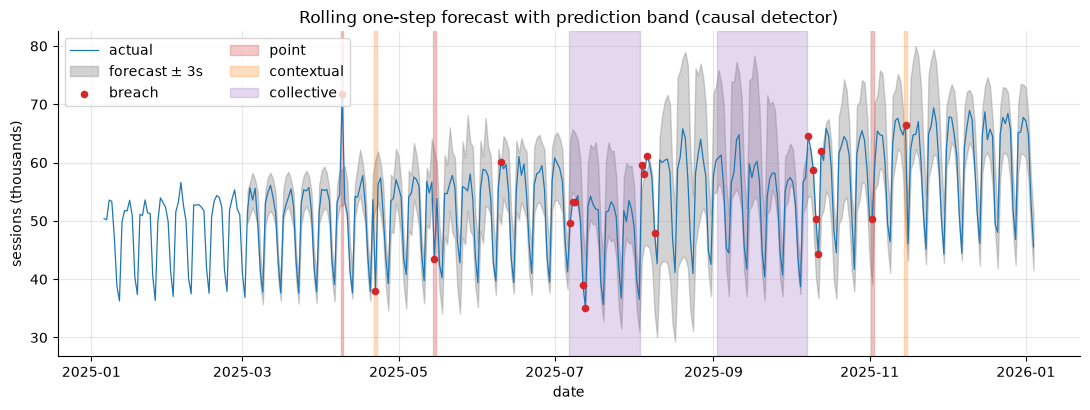

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(dates, sessions / 1000, lw=0.9, color="tab:blue", label="actual")
band_lo = np.exp(fc["pred"] - 3 * fc["sigma"]) / 1000
band_hi = np.exp(fc["pred"] + 3 * fc["sigma"]) / 1000
ax.fill_between(dates, band_lo, band_hi, color="tab:gray", alpha=0.35, label="forecast ± 3s")
ax.scatter(dates[fc_flag], sessions[fc_flag] / 1000, color="tab:red", s=20,
           zorder=3, label="breach")
mark_events(ax)
ax.set_title("Rolling one-step forecast with prediction band (causal detector)")
ax.set_xlabel("date"); ax.set_ylabel("sessions (thousands)")
ax.legend(loc="upper left", ncol=2)
plt.show()

Look closely at the level-shift window: the first few shifted days breach, then the band
**walks down onto the new level** — the shifted days entered the training window and became
the baseline. Alerts stop while the business is still broken. And during the drift, the
band tracks the decline almost perfectly: each day is only ~0.3% below yesterday's baseline,
far inside a 3σ band. **One-step detectors are structurally blind to slow drifts** — not
badly tuned, blind. Both failure modes get fixed below; both are favorite interview probes.

## 4. Method 2b — the changepoint watchdog: week-over-week CUSUM

The fix for collective anomalies has three parts, each answering one failure above:

1. **A baseline that cannot chase the anomaly.** Monitor the week-over-week log change
   `d7[t] = log y[t] − log y[t−7]`, standardized by its own trailing median/MAD (excluding
   today). Differencing at the seasonal lag removes the weekly shape, and the trailing
   median of `d7` absorbs steady growth — no regression, no trend extrapolation, strictly
   causal. During a drift, `d7` sits *persistently* below its normal value; at a level
   shift, seven consecutive readings scream −12%.
2. **Winsorize before accumulating** (clip the z at ±3). Single-day monsters are Method 2's
   job, and an 8σ spike would otherwise both ring the accumulator on the day *and* echo a
   week later when it becomes the comparison point. Clipping — not deleting — keeps genuine
   multi-day evidence flowing.
3. **Accumulate evidence instead of testing each day alone.** Two-sided CUSUM:
   \(S^+_t = \max(0, S^+_{t-1} + z_t - k)\), mirrored for \(S^-\); alarm when a sum crosses
   \(h\), then reset. With `k` = 0.25 (sensitive to small persistent deviations) and
   `h` = 5, a steady ~0.8σ deviation alarms in under two weeks while white noise almost
   never accumulates.

This is the same statistic as manufacturing SPC charts and the drift detectors in ML model
monitoring — one idea, many wrappers.

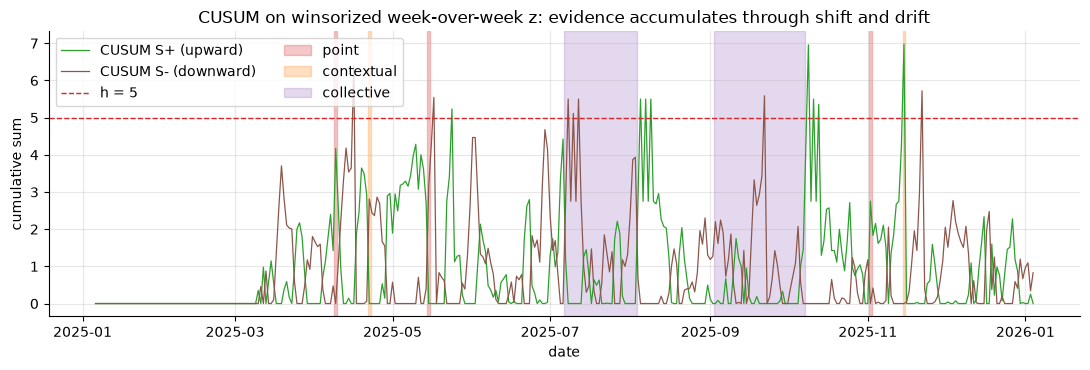

CUSUM alarms on 15 days


In [7]:
def cusum(z, k=0.5, h=5.0):
    """Two-sided CUSUM on standardized residuals; resets after each alarm."""
    n = len(z)
    alarms = np.zeros(n, dtype=bool)
    sp_path, sn_path = np.zeros(n), np.zeros(n)
    sp = sn = 0.0
    for t in range(n):
        if np.isnan(z[t]):
            continue
        sp = max(0.0, sp + z[t] - k)
        sn = max(0.0, sn - z[t] - k)
        sp_path[t], sn_path[t] = sp, sn
        if sp > h or sn > h:
            alarms[t] = True
            sp = sn = 0.0
    return alarms, sp_path, sn_path

ly_s = pd.Series(ly, index=dates)
d7 = ly_s.diff(7)                                   # week-over-week log change
ref_med = d7.shift(1).rolling(56).median()          # what a normal w-o-w change looks like
ref_mad = d7.shift(1).rolling(56).apply(
    lambda w: median_abs_deviation(w, scale="normal"), raw=True)
z7 = ((d7 - ref_med) / ref_mad).clip(-3, 3).to_numpy()   # winsorized w-o-w z

cusum_flag, sp_path, sn_path = cusum(z7, k=0.25, h=5.0)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(dates, sp_path, lw=0.9, color="tab:green", label="CUSUM S+ (upward)")
ax.plot(dates, sn_path, lw=0.9, color="tab:brown", label="CUSUM S- (downward)")
ax.axhline(5.0, color="tab:red", ls="--", lw=1, label="h = 5")
mark_events(ax)
ax.set_title("CUSUM on winsorized week-over-week z: evidence accumulates through shift and drift")
ax.set_xlabel("date"); ax.set_ylabel("cumulative sum")
ax.legend(loc="upper left", ncol=2)
plt.show()
print(f"CUSUM alarms on {cusum_flag.sum()} days")

Read the S⁻ path: at the level shift, seven clipped −3σ readings pile up and it alarms on
day 1, then re-alarms while the shift persists; through the drift it climbs slowly — days
individually inside noise become overwhelming *jointly*. That is the definition of a
collective anomaly, and the reason accumulation (not a bigger threshold) is the answer.
Three honest costs, visible in the plot:

- **Recovery edges alarm too** (just after the shift ends and again after the drift is
  fixed): to a persistent-change detector, the way *back* to normal is also a persistent
  change. Real systems route these as "recovery" annotations on the open incident.
- **Faint differencing echoes**: a big point anomaly re-enters `d7` a week later as the
  comparison point; clipping blunts this but a few off-by-a-week alarms can survive.
  Production fix: mask known incident days out of the lag (Pitfall 2's masking, reused).
- **A CUSUM alarm is a statement about the recent path, not about "today"** — the alarm
  date tells you the evidence crossed a line, not when the problem started; you read the
  changepoint off the path, not off the alarm timestamp.

## 5. Method 3 — IsolationForest on engineered features

The ML route: turn each day into a feature vector and let an unsupervised detector isolate
odd days. The critical design decision is **features, not the model** — IsolationForest has
no idea your series has a weekly cycle unless you encode it. We use causal (trailing-only)
features:

- `d1`, `d7`: 1-day and 7-day log-differences (jump detectors),
- `dev_dow`: deviation from the median of the last 4 same-weekday values (the contextual
  feature — this is what lets it see "wrong shape for a Tuesday"),
- `dev_7d`: deviation from the trailing 7-day median (local level feature).

`contamination` sets what fraction of days get flagged — note that this is **an alert
budget in disguise**, chosen a priori, not learned. Exercise 3 shows how badly this method
degrades if you feed it raw values without the contextual features.

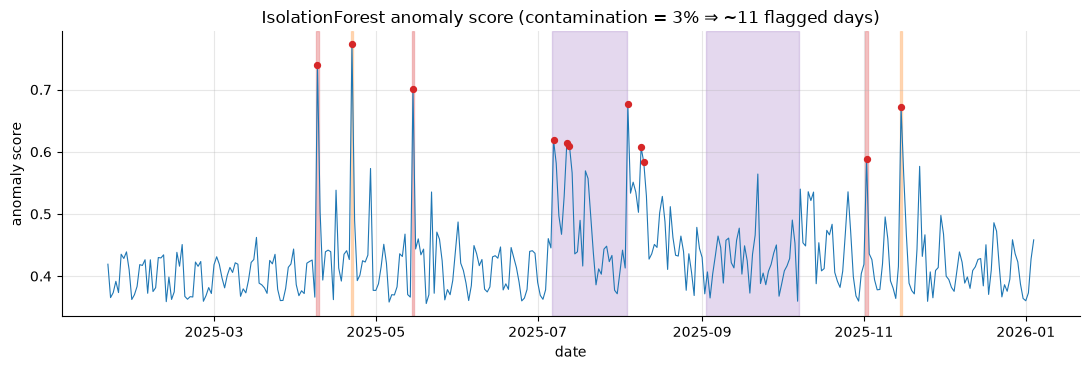

IsolationForest flags 11 days


In [8]:
feats = pd.DataFrame({
    "d1": ly_s.diff(1),
    "d7": ly_s.diff(7),
    "dev_dow": ly_s - ly_s.groupby(dow).transform(
        lambda s: s.shift(1).rolling(4, min_periods=2).median()),
    "dev_7d": ly_s - ly_s.shift(1).rolling(7).median(),
})
valid = feats.dropna()

iso = IsolationForest(n_estimators=300, contamination=0.03, random_state=42)
iso_pred = iso.fit_predict(valid.to_numpy())
iso_score = -iso.score_samples(valid.to_numpy())          # higher = more anomalous

if_flag = np.zeros(n_days, dtype=bool)
if_flag[dates.get_indexer(valid.index[iso_pred == -1])] = True

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(valid.index, iso_score, lw=0.8, color="tab:blue")
ax.scatter(valid.index[iso_pred == -1], iso_score[iso_pred == -1],
           color="tab:red", s=18, zorder=3)
mark_events(ax)
ax.set_title("IsolationForest anomaly score (contamination = 3% ⇒ ~11 flagged days)")
ax.set_xlabel("date"); ax.set_ylabel("anomaly score")
plt.show()
print(f"IsolationForest flags {if_flag.sum()} days")

## 6. Scoreboard: precision/recall/F1 and — the real lesson — who catches what, how fast

Two complementary evaluations, because they answer different questions:

- **Point-wise (day-level) precision/recall/F1**: treats every labeled anomalous day as a
  positive. Honest about alert volume, but it structurally punishes changepoint detectors —
  catching a 28-day shift on day 2 and holding one alarm scores 1/28 recall (Pitfall 3).
- **Event-wise detection + delay**: for each of the 7 labeled events, did the method fire
  *within the event window*, and how many days after onset? This is what your VP actually
  asks: "when did we know?"

We evaluate from day 84 onward so every method is past its burn-in and sees the same days.

In [9]:
methods = {
    "STL + MAD z": stl_flag,
    "Rolling forecast PI": fc_flag,
    "CUSUM watchdog": cusum_flag,
    "IsolationForest": if_flag,
}

EVAL_START = 84
ev_mask = np.arange(n_days) >= EVAL_START
y_true = is_anom[ev_mask]

point_rows = []
for name, fl in methods.items():
    y_hat = fl[ev_mask]
    point_rows.append({
        "method": name,
        "flagged days": int(y_hat.sum()),
        "precision": precision_score(y_true, y_hat, zero_division=0),
        "recall": recall_score(y_true, y_hat, zero_division=0),
        "F1": f1_score(y_true, y_hat, zero_division=0),
    })
point_table = pd.DataFrame(point_rows).set_index("method")
print("POINT-WISE metrics (day-level, days >= 84;",
      f"{int(y_true.sum())} of {int(ev_mask.sum())} days are labeled anomalous)")
print(point_table)

POINT-WISE metrics (day-level, days >= 84; 68 of 280 days are labeled anomalous)
                     flagged days  precision  recall     F1
method                                                     
STL + MAD z                    27      0.519   0.206  0.295
Rolling forecast PI            20      0.500   0.147  0.227
CUSUM watchdog                 15      0.333   0.074  0.120
IsolationForest                11      0.727   0.118  0.203


In [10]:
def detection_delay(flags, ev):
    idxs = np.arange(ev["start"], ev["end"] + 1)
    hits = idxs[flags[idxs]]
    return int(hits[0] - ev["start"]) if hits.size else None

delay_rows = []
for ev in events:
    row = {"event": ev["name"], "type": ev["type"],
           "len (days)": ev["end"] - ev["start"] + 1}
    for name, fl in methods.items():
        d = detection_delay(fl, ev)
        row[name] = "MISS" if d is None else f"day {d}"
    delay_rows.append(row)
delay_table = pd.DataFrame(delay_rows).set_index(["type", "event"]).sort_index()
print("EVENT-WISE detection (first alarm inside the event window; delay from onset)")
print(delay_table.to_string())

EVENT-WISE detection (first alarm inside the event window; delay from onset)
                             len (days) STL + MAD z Rolling forecast PI CUSUM watchdog IsolationForest
type       event                                                                                      
collective drift 0 to -12%           35       day 4                MISS         day 19            MISS
           level shift -12%          28       day 0               day 0          day 1           day 0
contextual flash-sale Sat             1       day 0               day 0          day 0           day 0
           holiday Tue                1       day 0               day 0           MISS           day 0
point      outage dip -22%            1       day 0               day 0           MISS           day 0
           spike +28%                 1       day 0               day 0           MISS           day 0
           subtle spike +8%           1       day 0               day 0           MISS           da

In [11]:
# Autopsy of one suspicious entry before drawing conclusions: STL appears to flag days
# inside the drift window. Look at the SIGN of those residuals.
drift_win = np.arange(240, 275)
stl_hits = drift_win[stl_flag[drift_win]]
print("STL flags inside the (downward) drift window:", stl_hits)
print("their robust z-scores:", np.round(stl_z[stl_hits], 1))
print("\nMostly POSITIVE z during a downward drift: STL's two-sided trend has already bent")
print("toward the future decline, leaving early-drift actuals sitting ABOVE it. This is a")
print("retrospective-decomposition artifact, not a detection - a causal detector could never")
print("produce it. Always check the sign and mechanism of a 'catch' before crediting it.")

STL flags inside the (downward) drift window: [244 247 248 252 272]
their robust z-scores: [ 4.7  3.9  4.9  4.5 -3.9]

Mostly POSITIVE z during a downward drift: STL's two-sided trend has already bent
toward the future decline, leaving early-drift actuals sitting ABOVE it. This is a
retrospective-decomposition artifact, not a detection - a causal detector could never
produce it. Always check the sign and mechanism of a 'catch' before crediting it.


In [12]:
event_recall = {
    name: np.mean([detection_delay(fl, ev) is not None for ev in events])
    for name, fl in methods.items()
}
print("event-level recall (share of the 7 events caught):")
for name, r in event_recall.items():
    print(f"  {name:22s} {r:.0%}")

event-level recall (share of the 7 events caught):
  STL + MAD z            100%
  Rolling forecast PI    86%
  CUSUM watchdog         43%
  IsolationForest        86%


### Read the table by column — the mapping is the design lesson

| anomaly class | who catches it | why |
|---|---|---|
| **point** (big spike/dip) | STL, forecast PI, IsolationForest — same day. The CUSUM watchdog is blind **by design** (winsorizing throws away single-day evidence) | an 8–10σ residual is loud under any residual-based score; the division of labor between fast detector and watchdog is deliberate |
| **point, subtle** (+8%) | the residual methods at their current thresholds — but it drops out of the forecast detector at z ≥ 3.5 (next section) | near-threshold anomalies are a *budget* decision, not a modeling decision |
| **contextual** (holiday Tue, flash-sale Sat) | seasonality-aware methods: STL, rolling forecast, and IF *only because* of its `dev_dow` feature | the raw values are globally normal; only a model that knows "what a Tuesday should be" sees them. Drop the context feature and IF goes blind (Exercise 3) |
| **collective — level shift** | forecast PI flags the onset instantly, then adapts and goes silent (Pitfall 2); STL sees only the edges (trend absorbs); IF sees the jump days; the watchdog alarms on day 1 **and keeps re-alarming** while it persists | one-day tests can only see the first shifted days; representing "still broken" requires accumulation plus a baseline that can't chase |
| **collective — drift** | the watchdog **only** — ~3 weeks in, when the drift is ~7% deep. Forecast PI and IF miss it outright; STL's in-window flags are the wrong-signed artifact autopsied above | no single day is anomalous; only the *sum* of days is. Detection delay, not hit/miss, is the right success metric |

(One footnote: the watchdog's "day 0" on the flash-sale is incidental — its accumulator was
still elevated from the drift recovery. A CUSUM alarm date is a property of the path, not
of the day; never read it as "today is the anomaly".)

Three senior conclusions:

1. **No single detector dominates — by structure, not by tuning.** Production systems run a
   fast point/contextual detector (forecast + PI) *and* a slow collective watchdog
   (CUSUM-style) in parallel; they answer different questions ("is today broken?" vs "has
   something quietly changed?"). The watchdog's low event recall here is the design working.
2. **The subtle spike is threshold economics, not modeling.** Any method catches it by
   paying more false positives — Section 7 makes that trade explicit.
3. **Detection delay is a first-class metric.** For collective anomalies, "caught: yes/no"
   hides everything that matters; a drift caught after 40 days may be worthless.

## 7. Alert design reality: budgets, fatigue, and why static thresholds fail

### 7.1 The static threshold autopsy

The most common first attempt in industry: "page if sessions < X". On a growing, seasonal
metric this fails in **both directions**, and it's worth seeing the arithmetic. A floor set
near the *average* sits above normal weekend traffic → pages on ordinary Sundays. A floor
set safely below the weekly minimum loses sensitivity as the metric grows — calibrated in
Q1, it sleeps through a −22% outage and an entire −12% drift later in the year, grazing
only the deepest days of the level shift. And a floor is one-sided by construction: the
+28% bot wave is also an incident, and no floor sees upward anomalies at all.

In [13]:
train_slice = slice(0, 56)                     # ops team calibrates on the first 8 weeks
floor_avg = 0.85 * sessions[train_slice].mean()      # "15% below normal"
floor_min = 0.97 * sessions[train_slice].min()       # "just under the lowest we've seen"

for name, floor in [("floor at 85% of mean", floor_avg),
                    ("floor below weekly min", floor_min)]:
    fl = sessions < floor
    fl[:56] = False                            # only score after calibration window
    false_alarm_days = int((fl & ~is_anom).sum())
    caught = [ev["name"] for ev in events if detection_delay(fl, ev) is not None]
    print(f"{name} ({floor/1000:,.1f}k):")
    print(f"   false-alarm days: {false_alarm_days:3d}   events caught: "
          f"{caught if caught else 'NONE of 7'}")

floor at 85% of mean (41.1k):
   false-alarm days:  17   events caught: ['holiday Tue', 'level shift -12%', 'drift 0 to -12%']
floor below weekly min (35.2k):
   false-alarm days:   0   events caught: ['level shift -12%']


One threshold pages on 17 perfectly normal (mostly weekend) days and still catches only
the downward events it happens to straddle; the other never false-alarms and detects
almost nothing. Both get *worse* over time, because growth keeps moving the metric's
normal range away from any constant. **The fix is not a better constant, it's a moving,
seasonality-aware baseline**: alert on `actual vs forecast`, where the forecast carries
the trend and the weekly shape. That's exactly Method 2 — the static threshold's job
(encode "normal") is done by a model, and the threshold's only remaining job is to set
the sensitivity. Which raises the real question: at what sensitivity?

### 7.2 Thresholds are alert budgets

Without labels you cannot pick `z` by F1. What you *can* control is the **alert budget**:
how many alerts per month your on-call rotation will actually investigate before they start
ignoring the channel. Alert fatigue is a precision problem at low base rates — the same
arithmetic as fraud triage in
[../04_ml_tabular/04_imbalanced_fraud.ipynb](../04_ml_tabular/04_imbalanced_fraud.ipynb):
if responders see mostly false alarms, response quality collapses for the true ones. So
invert the problem: pick the alert volume you can afford, then read off the threshold.

Alert budget curve (rolling-forecast detector):
     alert days/yr  alerts/month  false-alarm days  event recall
z                                                               
2.0             40         4.343                27         1.000
2.5             27         2.931                16         0.857
3.0             20         2.171                10         0.857
3.5             14         1.520                 5         0.714
4.0             11         1.194                 4         0.714
5.0              6         0.651                 1         0.714


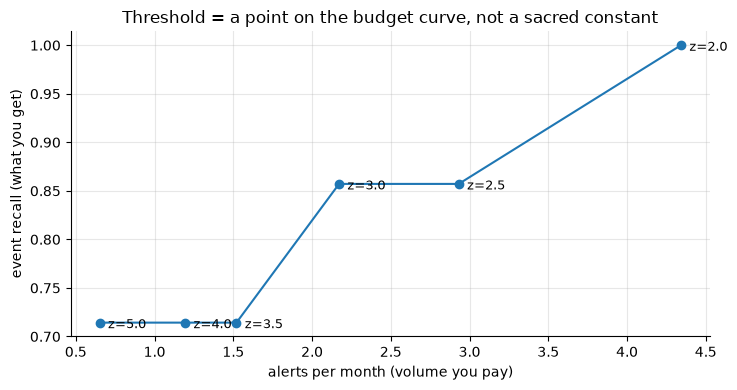

In [14]:
z_grid = [2.0, 2.5, 3.0, 3.5, 4.0, 5.0]
months_eval = ev_mask.sum() / 30.4
budget_rows = []
fc_z = np.abs(fc["z"].to_numpy())
for zt in z_grid:
    fl = fc_z > zt
    fl = np.where(np.isnan(fc["z"].to_numpy()), False, fl)
    n_alerts = int(fl[ev_mask].sum())
    fa_days = int((fl & ~is_anom)[ev_mask].sum())
    ev_rec = np.mean([detection_delay(fl, ev) is not None for ev in events])
    budget_rows.append({"z": zt, "alert days/yr": n_alerts,
                        "alerts/month": n_alerts / months_eval,
                        "false-alarm days": fa_days, "event recall": ev_rec})
budget = pd.DataFrame(budget_rows).set_index("z")
print("Alert budget curve (rolling-forecast detector):")
print(budget)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(budget["alerts/month"], budget["event recall"], marker="o", color="tab:blue")
for zt, row in budget.iterrows():
    ax.annotate(f"z={zt}", (row["alerts/month"], row["event recall"]),
                textcoords="offset points", xytext=(6, -4), fontsize=9)
ax.set_xlabel("alerts per month (volume you pay)")
ax.set_ylabel("event recall (what you get)")
ax.set_title("Threshold = a point on the budget curve, not a sacred constant")
plt.show()

Loosening from z=3.5 to z=2.5 is what buys the subtle +8% spike — at the price of extra
alert days per month. Whether that trade is good depends on the *metric's* value, not on
statistics: for checkout revenue, buy it; for a vanity dashboard, don't. In a real platform
this is tiered: **top-line KPIs get tight budgets and paging; the long tail gets loose
budgets and a daily digest.** And with 500 dashboards, even a 1%-per-metric-per-day false
alarm rate ≈ 5 spurious pages *every day* — per-metric thresholds must be set from a
*global* budget (this is the multiple-testing problem wearing an ops costume).

### 7.3 Holiday handling: anomalous ≠ actionable

Our injected "Tuesday that behaves like a Sunday" is statistically a violation and every
seasonal detector correctly screams. But if that Tuesday is July 4th, the alert is *correct
and useless* — the definition of fatigue. Real systems maintain a **holiday calendar** as a
first-class input: (a) with multiple years of history, add holiday regressors so the
forecast *expects* the dip (including bridge days and moving holidays like Easter or
Ramadan); (b) with one year of data, at minimum suppress-and-annotate: the detector still
records the deviation, but routes it as "expected event" instead of paging.

In [15]:
known_holidays = np.zeros(n_days, dtype=bool)
known_holidays[106] = True                     # the calendar knows about this Tuesday

fc_flag_hol = fc_flag & ~known_holidays
print(f"forecast-PI alert days: {fc_flag.sum()} -> {fc_flag_hol.sum()} "
      "after holiday suppression")
print(f"holiday Tue alerted before: {bool(fc_flag[106])}, after: {bool(fc_flag_hol[106])} "
      "(recorded as annotation, not page)")

forecast-PI alert days: 20 -> 19 after holiday suppression
holiday Tue alerted before: True, after: False (recorded as annotation, not page)


Note what we did **not** do: delete the day from history. The holiday's low value would
otherwise contaminate trailing baselines for the next weeks. Production practice is to
keep the observation, flag it as a known event, and *exclude it from training windows* —
the same masking mechanism as Pitfall 2's fix.

## 8. Root cause, step one: dimensional breakdown

An alert without localization is homework, not an answer. The first triage move for an
additive metric (sessions, orders, revenue) is to break the top-line delta into per-segment
contributions: `contribution(s) = (actual_s − expected_s) / Σ(actual − expected)`, with each
segment's expectation from its own seasonal baseline (here: median of the last 4 same
weekdays). We simulate the platform dimension for our level-shift incident — the SDK bug
only broke Android logging.

Dimensional breakdown of the 2025-07-08 alert (sessions by platform):
         expected   actual   delta  own move %  contribution %
segment                                                       
android   23638.9  16124.6 -7514.2       -31.8           116.1
web       14416.2  14697.2   281.0         1.9            -4.3
ios       19967.3  20730.4   763.1         3.8           -11.8


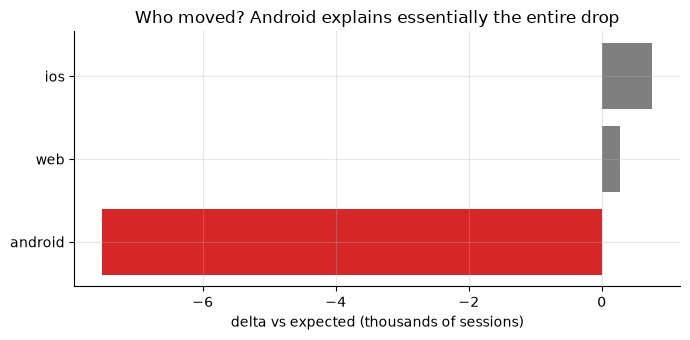

In [16]:
shares = {"android": 0.40, "ios": 0.35, "web": 0.25}
segments = pd.DataFrame(
    {name: clean * share * np.exp(rng.normal(0.0, 0.02, n_days))
     for name, share in shares.items()},
    index=dates,
)
segments.loc[dates[182:210], "android"] *= 0.70          # the actual bug: android -30%

t0 = 183                                                  # the morning after the alert fired
def same_dow_expected(s, t, k=4):
    return float(np.median([s.iloc[t - 7 * j] for j in range(1, k + 1)]))

rows = []
for c in segments.columns:
    exp_v = same_dow_expected(segments[c], t0)
    act_v = float(segments[c].iloc[t0])
    rows.append({"segment": c, "expected": exp_v, "actual": act_v,
                 "delta": act_v - exp_v, "own move %": 100 * (act_v / exp_v - 1)})
rc = pd.DataFrame(rows).set_index("segment")
rc["contribution %"] = 100 * rc["delta"] / rc["delta"].sum()
rc = rc.sort_values("contribution %", ascending=False)
print(f"Dimensional breakdown of the {dates[t0].date()} alert (sessions by platform):")
print(rc.round(1))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(rc.index, rc["delta"] / 1000, color=["tab:red" if d < 0 else "tab:gray"
                                             for d in rc["delta"]])
ax.set_xlabel("delta vs expected (thousands of sessions)")
ax.set_title("Who moved? Android explains essentially the entire drop")
plt.show()

One table turns "sessions are down 12%" into "Android is down 30%, everything else is
flat" — which immediately suggests *release notes, SDK version adoption curves, crash
dashboards*, and rules out marketing, seasonality, and macro stories. Practical notes for
the real thing:

- Scan **multiple dimensions** (platform × country × app version × acquisition channel) and
  rank segments by contribution — but beware the multiple-comparison flood: with hundreds
  of cells, some segment always looks "off". Rank by *contribution to the top-line delta*,
  not by per-segment z-score, so small noisy cells can't dominate.
- This decomposition is exact only for **additive** metrics. For ratio metrics (conversion,
  ARPU) you must separate *within-segment* moves from *mix shift* — a Simpson's-flavored
  decomposition, not a simple subtraction.
- The most common root cause of a KPI anomaly is **the data pipeline, not the business**:
  late-arriving partitions, tracking releases, bot filtering changes. "Is it real or is it
  logging?" is always question zero — a metric like `rows ingested per source` is itself a
  KPI worth monitoring.

## 9. Pitfalls — each one demonstrated

### Pitfall 1: non-robust baselines — one spike masks the next incident

Score residuals with mean/std over a trailing window and a single large spike inflates the
std so much that a *real* moderate dip a few days later scores as unremarkable. This is
**masking**, and it's why every scale estimate in this notebook is a MAD.

In [17]:
snippet = 1 + rng.normal(0.0, 0.02, 60)        # 60 days of a flat, noisy metric
snippet[40] = 1.45                             # day 40: huge spike (bot wave)
snippet[45] = 0.92                             # day 45: real -8% dip (~4 sigma) five days later

win = snippet[17:45]                           # trailing 28-day window at day 45 (has the spike)
z_std = (snippet[45] - win.mean()) / win.std(ddof=1)
z_mad = (snippet[45] - np.median(win)) / median_abs_deviation(win, scale="normal")
print(f"day-45 dip scored with trailing mean/std : z = {z_std:5.2f}  -> NOT flagged at |z|>3")
print(f"day-45 dip scored with median/MAD        : z = {z_mad:5.2f}  -> flagged")

day-45 dip scored with trailing mean/std : z = -1.05  -> NOT flagged at |z|>3
day-45 dip scored with median/MAD        : z = -3.76  -> flagged


### Pitfall 2: the adaptation trap — the baseline learns the outage

Section 3 showed the forecast band walking down onto the level shift. Here is the failure
quantified, and the standard fix: **feedback masking** — days the detector flagged are
excluded from future training windows, so the baseline keeps representing "normal" until a
human explicitly re-baselines.

alert days inside the 28-day level shift:
  plain rolling forecast :  5 / 28  (adapts, goes silent while still broken)
  with feedback masking  : 28 / 28  (keeps alarming until re-baselined)


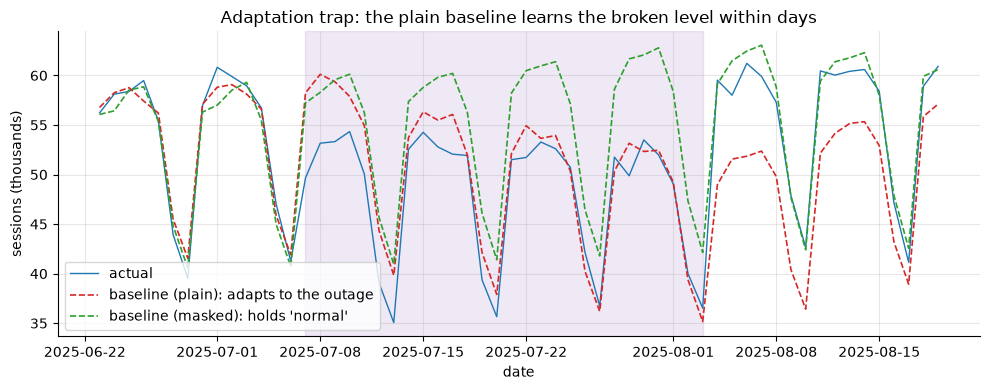

In [18]:
fc_masked = rolling_forecast(ly, dow, window=56, z_thresh=3.0, exclude_flagged=True)
fm_flag = fc_masked["flag"].to_numpy()

shift_idx = np.arange(182, 210)
print("alert days inside the 28-day level shift:")
print(f"  plain rolling forecast : {int(fc_flag[shift_idx].sum()):2d} / 28  "
      "(adapts, goes silent while still broken)")
print(f"  with feedback masking  : {int(fm_flag[shift_idx].sum()):2d} / 28  "
      "(keeps alarming until re-baselined)")

zoom = slice(168, 226)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dates[zoom], sessions[zoom] / 1000, lw=1.0, color="tab:blue", label="actual")
ax.plot(dates[zoom], np.exp(fc["pred"].to_numpy()[zoom]) / 1000, lw=1.2,
        color="tab:red", ls="--", label="baseline (plain): adapts to the outage")
ax.plot(dates[zoom], np.exp(fc_masked["pred"].to_numpy()[zoom]) / 1000, lw=1.2,
        color="tab:green", ls="--", label="baseline (masked): holds 'normal'")
ax.axvspan(dates[182], dates[209], color="tab:purple", alpha=0.15)
ax.set_title("Adaptation trap: the plain baseline learns the broken level within days")
ax.set_xlabel("date"); ax.set_ylabel("sessions (thousands)")
ax.legend(loc="lower left")
plt.show()

The masked detector holds the pre-incident baseline through the entire outage — and, as a
bonus, does not fire a spurious "recovery spike" alert when the metric jumps back (to the
plain detector, the recovery is a +14% anomaly against its corrupted baseline!). The trap
has a mirror image, though: if the shift is a *legitimate* new normal (a launch, a pricing
change), masking means the detector alarms forever. There is no statistical resolution —
level shifts require a **human decision** ("incident" vs "new baseline") and the system
needs an explicit re-baseline / annotation action. That asymmetry is the heart of the
"level shift vs outlier" interview question.

### Pitfall 3: point-wise F1 misleads on window anomalies

In [19]:
f1s = point_table["F1"].sort_values(ascending=False)
print("day-level F1 ranking:")
print(f1s.round(3).to_string())
print(f"\n- The watchdog is DEAD LAST on day-level F1 ({point_table.loc['CUSUM watchdog', 'F1']:.2f})")
print("  yet it is the only method that catches the drift at all and it flags the level")
print("  shift within a day. Its alarms are sparse by design (alarm -> reset -> re-arm),")
print("  so day-level recall over a 35-day labeled window is guaranteed to look terrible.")
print(f"- STL tops the table ({point_table.loc['STL + MAD z', 'F1']:.2f}) yet is two-sided - it")
print("  could not have paged anyone in real time, and part of its 'recall' inside the")
print("  drift window is the wrong-signed artifact autopsied in Section 6.")
print("\nDay-level F1 neither ranks deployability nor changepoint value. Score single-day")
print("anomalies day-wise; score changepoints by event recall AND detection delay.")

day-level F1 ranking:
method
STL + MAD z            0.295
Rolling forecast PI    0.227
IsolationForest        0.203
CUSUM watchdog         0.120

- The watchdog is DEAD LAST on day-level F1 (0.12)
  yet it is the only method that catches the drift at all and it flags the level
  shift within a day. Its alarms are sparse by design (alarm -> reset -> re-arm),
  so day-level recall over a 35-day labeled window is guaranteed to look terrible.
- STL tops the table (0.29) yet is two-sided - it
  could not have paged anyone in real time, and part of its 'recall' inside the
  drift window is the wrong-signed artifact autopsied in Section 6.

Day-level F1 neither ranks deployability nor changepoint value. Score single-day
anomalies day-wise; score changepoints by event recall AND detection delay.


### Pitfall 4: modeling a multiplicative metric on the raw scale

On the raw scale, residual spread grows with the level of a growing metric, so one
threshold cannot be right in both January and December. On the log scale the noise is
homoskedastic by construction (a 2.5% wiggle is 2.5% all year).

In [20]:
resid_raw = STL(pd.Series(sessions, index=dates), period=7, robust=True).fit().resid.to_numpy()
q1, q4 = slice(0, 84), slice(280, 364)
ratio_raw = (median_abs_deviation(resid_raw[q4], scale="normal")
             / median_abs_deviation(resid_raw[q1], scale="normal"))
ratio_log = (median_abs_deviation(stl_resid[q4], scale="normal")
             / median_abs_deviation(stl_resid[q1], scale="normal"))
print(f"STL residual spread, Q4/Q1 ratio -- raw scale: {ratio_raw:.2f}   log scale: {ratio_log:.2f}")
print("A raw-scale threshold tuned in Q1 over-alerts (or, tuned in Q4, under-alerts) later.")

STL residual spread, Q4/Q1 ratio -- raw scale: 1.31   log scale: 1.13
A raw-scale threshold tuned in Q1 over-alerts (or, tuned in Q4, under-alerts) later.


## 10. Interview corner

**Q1. Design metric-anomaly alerting for 500 dashboards. Walk me through it.**
Strong answer outline:
- *One standard pipeline, not 500 bespoke models*: seasonality-aware baseline (rolling
  forecast or STL-style decomposition) → standardized residual → threshold. Per-metric
  config is limited to metric class (traffic-like, revenue-like, count-with-zeros, ratio)
  and importance tier.
- *Two detectors in parallel per metric*: fast interval-breach for point/contextual, slow
  CUSUM-style accumulator for shifts/drifts — they answer different questions.
- *Global alert budget, tiered*: 500 metrics × even 1% daily FPR = 5 junk pages/day, so
  thresholds derive from a budget (top KPIs: tight budget + paging; long tail: digest).
  This is multiple testing in ops clothing.
- *Dedup and correlation grouping*: one upstream incident moves 50 metrics; group alerts by
  time + dimension hierarchy and page once, on the root-most metric.
- *Calendar and change-event integration*: holidays, deploys, experiment launches as
  annotations/regressors; *feedback loop*: ack/mute/false-alarm labels feed threshold tuning.
- *Data-quality first*: freshness/completeness monitors on the pipelines, because most "KPI
  anomalies" are logging anomalies.

**Q2. Level shift vs a one-day outlier — why does the treatment differ?**
- Different generative story: transient shock vs regime change; different action: an
  outlier is investigated, annotated, and *excluded* from baselines (winsorize/mask so it
  doesn't corrupt scale estimates); a level shift demands a *decision* — incident (fight it,
  keep the old baseline, keep alarming) or new normal (accept it, re-baseline deliberately).
- Detection differs too: outliers are one-day tests; shifts need accumulation/changepoint
  logic, and detection *delay* is the KPI.
- For forecasting downstream: deleting a level shift as if it were outliers destroys real
  signal; you instead add a step regressor or re-fit from the break.

**Q3. How do you tune thresholds without labels?**
- Flip the problem: fix the *alert budget* (alerts/week the team can investigate), set the
  threshold at the matching residual quantile per metric; empirical quantiles beat Gaussian
  z because residual tails are heavy.
- Backtest on history under a "mostly quiet" assumption — the alert *rate* is measurable
  even when correctness isn't.
- Inject synthetic anomalies (this notebook's method) to measure recall/delay at a given
  budget; it's the standard way to compare detectors offline.
- Harvest weak labels from operations: acked vs muted alerts, incident tickets, deploy
  rollbacks — enough for coarse calibration.

**Q4. Your one-step detector missed a 6-week revenue drift. What do you change?**
- Diagnose the structural cause: adaptive baseline chased the drift; each daily residual
  was sub-threshold. Add an accumulator (CUSUM/Page-Hinkley) against a baseline that
  *cannot chase the drift* — seasonal-lag differences (this notebook's watchdog) or a
  lagged/frozen reference; monitor weekly aggregates (drift compounds across a week); optionally
  test the fitted trend slope against its historical distribution.
- State the trade-off: accumulators detect small persistent changes at the cost of delay;
  quote expected detection delay at the tuned settings, not just hit/miss.

**Q5. An alert fired 10 minutes ago. First 15 minutes?**
- Question zero: real vs data artifact — pipeline freshness/completeness, partial-day data,
  tracking release in the deploy log.
- Localize: dimensional breakdown (platform/country/version/channel) by contribution to the
  delta; check correlated metrics up/downstream of the KPI (sessions vs orders vs revenue)
  to see where in the funnel it breaks.
- Context: calendar (holiday? marketing blast? experiment ramp?), then escalate with a
  quantified statement: "orders −18% vs forecast, entirely iOS US, started 09:40, matches
  app release 09:30."

**Q6. Why not just throw an autoencoder / fancy ML detector at every metric?**
- Cold start and scale: 500+ metrics with a year of daily data each is *small data*;
  forecast-residual methods are sample-efficient, and their alert rate is directly
  calibratable — with an opaque score you still must pick a threshold, i.e. the same budget
  problem, but now uninterpretable.
- On-call trust requires explainability: "3.8σ below the seasonal forecast" is actionable;
  "reconstruction error 0.37" is not.
- Where ML detectors earn their keep: high-frequency (minute-level) or genuinely
  multivariate settings (correlated metric fleets) — after the simple baseline is in place
  as the benchmark to beat.

## 11. Key takeaways

- Validate detectors on **simulated, labeled, typed anomalies** — it's the only way to know
  the type-coverage of your system, and the standard offline evaluation trick in industry.
- Taxonomy drives design: **point** anomalies need residual tests, **contextual** ones need
  a seasonal model (or context features), **collective** ones need accumulation (CUSUM) —
  no single detector covers all three; production runs a fast and a slow detector in parallel.
- Model **multiplicative metrics on the log scale**; estimate scale with **MAD, never std**
  — the residuals contain the very anomalies you're hunting (masking).
- Adaptive baselines *learn the outage*: use feedback masking, and treat level shifts as a
  human decision (incident vs re-baseline), not a statistical one.
- Static thresholds on growing seasonal metrics fail in both directions; the threshold's
  only legitimate job is sensitivity on a *residual*, and its value comes from an **alert
  budget**, tiered by metric importance — alert fatigue is a precision problem
  (see [../04_ml_tabular/04_imbalanced_fraud.ipynb](../04_ml_tabular/04_imbalanced_fraud.ipynb)).
- Score changepoint detectors by **event recall and detection delay**, not day-level F1.
- An alert's first deliverable is localization: **dimensional breakdown by contribution to
  the delta**, and always ask "is it the business or the logging?" first.
- Holidays: anomalous ≠ actionable — calendar-aware suppression/regressors, and keep flagged
  days out of training baselines.

## 12. Exercises

**Exercise 1 — persistence rules.** On-call wants fewer one-off pages. Modify the rolling
forecast alerts with a "2-of-3" persistence rule (alert only if today breaches and at least
2 of the last 3 days breach). Measure what happens to (a) false-alarm days, (b) detection of
the three point anomalies, (c) delay on the level shift. What does this tell you about
running a single alerting rule?

In [21]:
# --- Solution 1 ---
def persist_rule(flags, k=2, n=3):
    out = np.zeros_like(flags)
    for t in range(len(flags)):
        lo = max(0, t - n + 1)
        out[t] = flags[t] and flags[lo:t + 1].sum() >= k
    return out

fp_flag = persist_rule(fc_flag, k=2, n=3)
fa = lambda fl: int((fl & ~is_anom)[ev_mask].sum())
print(f"false-alarm days: plain {fa(fc_flag)}  ->  2-of-3 rule {fa(fp_flag)}")
for ev in events:
    if ev["type"] == "point":
        print(f"  {ev['name']:18s} plain: {detection_delay(fc_flag, ev)}   "
              f"2-of-3: {detection_delay(fp_flag, ev)}")
ev_shift = events[3]
print(f"  level shift delay  plain: day {detection_delay(fc_flag, ev_shift)}   "
      f"2-of-3: day {detection_delay(fp_flag, ev_shift)}")
print("\nPersistence buys precision on sustained incidents but is structurally unable to")
print("catch single-day anomalies (they can never satisfy 2-of-3), and adds +1 day of shift")
print("delay. Conclusion: run BOTH a fast severe-threshold rule and a slow persistent rule.")

false-alarm days: plain 10  ->  2-of-3 rule 6
  spike +28%         plain: 0   2-of-3: None
  outage dip -22%    plain: 0   2-of-3: None
  subtle spike +8%   plain: 0   2-of-3: None
  level shift delay  plain: day 0   2-of-3: day 1

Persistence buys precision on sustained incidents but is structurally unable to
catch single-day anomalies (they can never satisfy 2-of-3), and adds +1 day of shift
delay. Conclusion: run BOTH a fast severe-threshold rule and a slow persistent rule.


**Exercise 2 — CUSUM tuning and the delay/false-alarm trade.** Re-run the CUSUM watchdog
over `h ∈ {3, 5, 8, 12}` (keep `k = 0.25`). For each `h`, report detection delay on the
level shift and the drift, and the number of alarm days outside any labeled window. Where
would you operate for a paging alert vs a weekly-review report — and what happens to drift
detection when `h` gets large?

In [22]:
# --- Solution 2 ---
rows = []
for h in [3.0, 5.0, 8.0, 12.0]:
    al, _, _ = cusum(z7, k=0.25, h=h)
    rows.append({
        "h": h,
        "shift delay": detection_delay(al, events[3]),
        "drift delay": detection_delay(al, events[4]),
        "alarm days outside labels": int((al & ~is_anom).sum()),
    })
print(pd.DataFrame(rows).set_index("h").to_string())
print("\nLower h reacts faster but alarms more outside labeled windows (recovery edges and")
print("differencing echoes). Raising h buys quiet at the cost of delay - and past h ~ 8 the")
print("drift becomes UNDETECTABLE, not just late: the trailing d7 reference adapts to the")
print("drift before the sum can cross, so patience has a hard structural limit. Paging wants")
print("moderate h (few, confident alarms); a weekly metric-review digest can afford low h")
print("and earlier warnings. Same statistic, two products - the operating point is a")
print("product decision, not a modeling one.")

      shift delay  drift delay  alarm days outside labels
h                                                        
3.0             1         15.0                         19
5.0             1         19.0                         10
8.0             2          NaN                          4
12.0            4          NaN                          2

Lower h reacts faster but alarms more outside labeled windows (recovery edges and
differencing echoes). Raising h buys quiet at the cost of delay - and past h ~ 8 the
drift becomes UNDETECTABLE, not just late: the trailing d7 reference adapts to the
drift before the sum can cross, so patience has a hard structural limit. Paging wants
moderate h (few, confident alarms); a weekly metric-review digest can afford low h
and earlier warnings. Same statistic, two products - the operating point is a
product decision, not a modeling one.


**Exercise 3 — IsolationForest is only as good as its context features.** Refit the
IsolationForest using only "global" features (`log level` and `d1`), i.e., no day-of-week
deviation features. Compare which events it now catches. What does this imply about applying
generic outlier detectors to seasonal business metrics?

In [23]:
# --- Solution 3 ---
feats_naive = pd.DataFrame({"level": ly_s, "d1": ly_s.diff(1)}).dropna()
iso_n = IsolationForest(n_estimators=300, contamination=0.03, random_state=42)
pred_n = iso_n.fit_predict(feats_naive.to_numpy())
if_naive = np.zeros(n_days, dtype=bool)
if_naive[dates.get_indexer(feats_naive.index[pred_n == -1])] = True

comp = pd.DataFrame({
    "event": [ev["name"] for ev in events],
    "type": [ev["type"] for ev in events],
    "IF full features": ["MISS" if detection_delay(if_flag, ev) is None else "caught"
                          for ev in events],
    "IF level+d1 only": ["MISS" if detection_delay(if_naive, ev) is None else "caught"
                          for ev in events],
}).set_index(["type", "event"]).sort_index()
print(comp.to_string())
print("\nWithout the same-weekday deviation feature the detector cannot represent 'wrong for")
print("a Tuesday' - contextual anomalies are invisible, and its budget gets spent flagging")
print("ordinary weekend lows and growth extremes. The model was never the hard part; the")
print("features encoding 'context' were.")

                            IF full features IF level+d1 only
type       event                                             
collective drift 0 to -12%              MISS             MISS
           level shift -12%           caught           caught
contextual flash-sale Sat             caught             MISS
           holiday Tue                caught           caught
point      outage dip -22%            caught             MISS
           spike +28%                 caught           caught
           subtle spike +8%           caught             MISS

Without the same-weekday deviation feature the detector cannot represent 'wrong for
a Tuesday' - contextual anomalies are invisible, and its budget gets spent flagging
ordinary weekend lows and growth extremes. The model was never the hard part; the
features encoding 'context' were.
